In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !pip install -q chronos-forecasting holidays
    DATA_DIR = Path("data/raw")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if not (DATA_DIR / "train.csv").exists():
        from google.colab import files
        for name, content in files.upload().items():  # pick the 3 CSVs
            (DATA_DIR / name).write_bytes(content)
else:
    DATA_DIR = Path("../data/raw")

In [39]:
def load(path):
    return pd.read_csv(path, index_col="id", parse_dates=["id"], date_format="%Y-%m-%d %H")

train = load(DATA_DIR / "train.csv")
test = load(DATA_DIR / "test.csv")

print(train.shape, test.shape)
print(train.dtypes)
train.head()

(40991, 5) (504, 0)
valeur_NO2     float64
valeur_CO      float64
valeur_O3      float64
valeur_PM10    float64
valeur_PM25    float64
dtype: object


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
id,,,,,
2020-01-01 00:00:00,42.9,0.718,15.7,73.1,64.4
2020-01-01 01:00:00,33.6,0.587,10.1,74.8,66.0
2020-01-01 02:00:00,29.3,NaN,5.1,51.0,44.9
2020-01-01 03:00:00,30.5,0.246,7.2,27.7,25.1
2020-01-01 04:00:00,29.3,0.204,8.3,15.3,13.6


In [ ]:
print("train:", train.index.min(), train.index.max())
print("test: ", test.index.min(), test.index.max())

train: 2020-01-01 00:00:00 2024-09-03 22:00:00
test:  2024-09-03 23:00:00 2024-09-24 22:00:00


In [25]:
POLLUTANTS = ["valeur_NO2", "valeur_CO", "valeur_O3", "valeur_PM10", "valeur_PM25"]

assert list(train.columns) == POLLUTANTS

In [26]:
# sorted
print("sorted:", train.index.is_monotonic_increasing)

# duplicates
print("duplicated timestamps:", train.index.duplicated().sum())

# missing hours
full_range = pd.date_range(train.index.min(), train.index.max(), freq="h")
missing_hours = full_range.difference(train.index)
print("expected hours:", len(full_range), ", rows:", len(train))
print("missing hours:", len(missing_hours))

# train and test connect
print("gap train, test:", test.index[0] - train.index[-1])
print("test rows:", len(test))

sorted: True
duplicated timestamps: 0
expected hours: 40991 , rows: 40991
missing hours: 0
gap train, test: 0 days 01:00:00
test rows: 504


In [27]:
missing= pd.DataFrame({"n_missing":train.isna().sum(),"pct_missing":(train.isna().mean()*100).round(2)})
missing 

,n_missing,pct_missing
valeur_NO2,3297,8.04
valeur_CO,12529,30.57
valeur_O3,693,1.69
valeur_PM10,7167,17.48
valeur_PM25,1791,4.37


In [28]:
# share of missing values per year in pct
missing_per_year =(train.isna().groupby(train.index.year).mean() * 100).round(1)
print(missing_per_year)
# longest run of consecutive missing hours per pollutant
for col in POLLUTANTS:
    na = train[col].isna()
    runs = na.groupby((~na).cumsum()).sum()
    print(col, ", longest gap:", runs.max(), "h, gaps over 24h:", (runs > 24).sum())


      valeur_NO2  valeur_CO  valeur_O3  valeur_PM10  valeur_PM25
id                                                              
2020         9.1        6.9        5.2         15.3         15.6
2021        20.6       98.8        0.6         10.3          2.4
2022         1.2       33.8        0.6         23.5          0.9
2023         0.4        2.7        0.8         17.9          0.8
2024         9.2        1.2        1.1         21.8          1.1
valeur_NO2 , longest gap: 1500 h, gaps over 24h: 9
valeur_CO , longest gap: 10949 h, gaps over 24h: 9
valeur_O3 , longest gap: 131 h, gaps over 24h: 6
valeur_PM10 , longest gap: 90 h, gaps over 24h: 28
valeur_PM25 , longest gap: 493 h, gaps over 24h: 10


negative values: valeur_NO2      0
valeur_CO       0
valeur_O3      10
valeur_PM10     0
valeur_PM25     0
dtype: int64


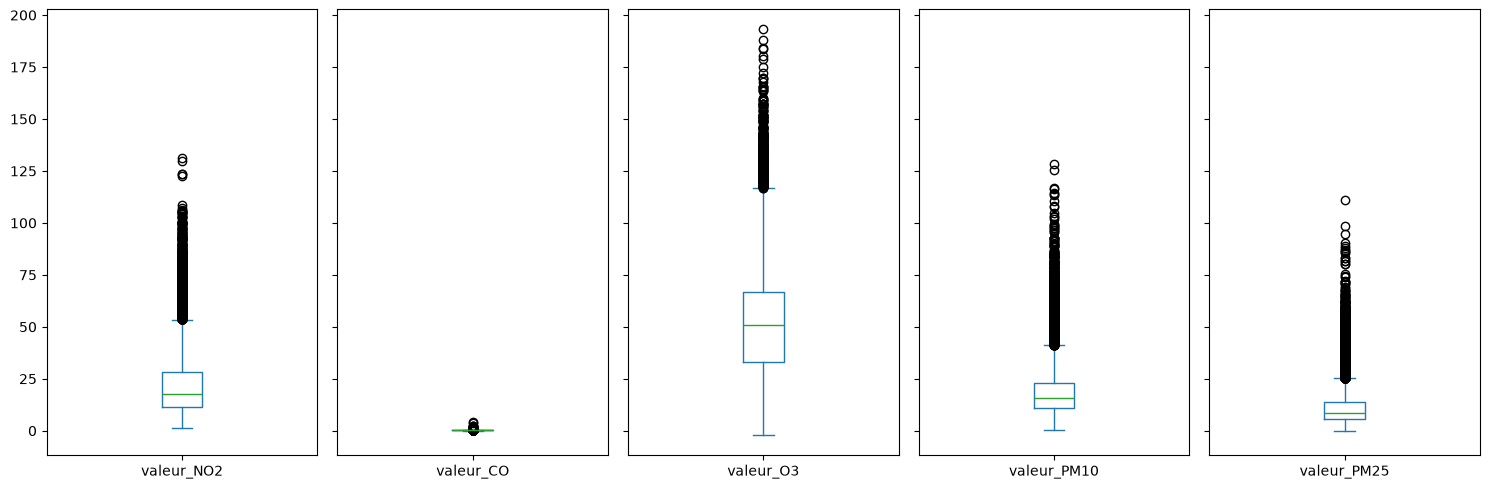

In [29]:
print("negative values:", (train < 0).sum())
train.quantile([0.5, 0.99, 0.999, 1.0]).T

train.plot(kind="box", subplots=True, layout=(1, 5),
           figsize=(15, 5), sharey=True)
plt.tight_layout()

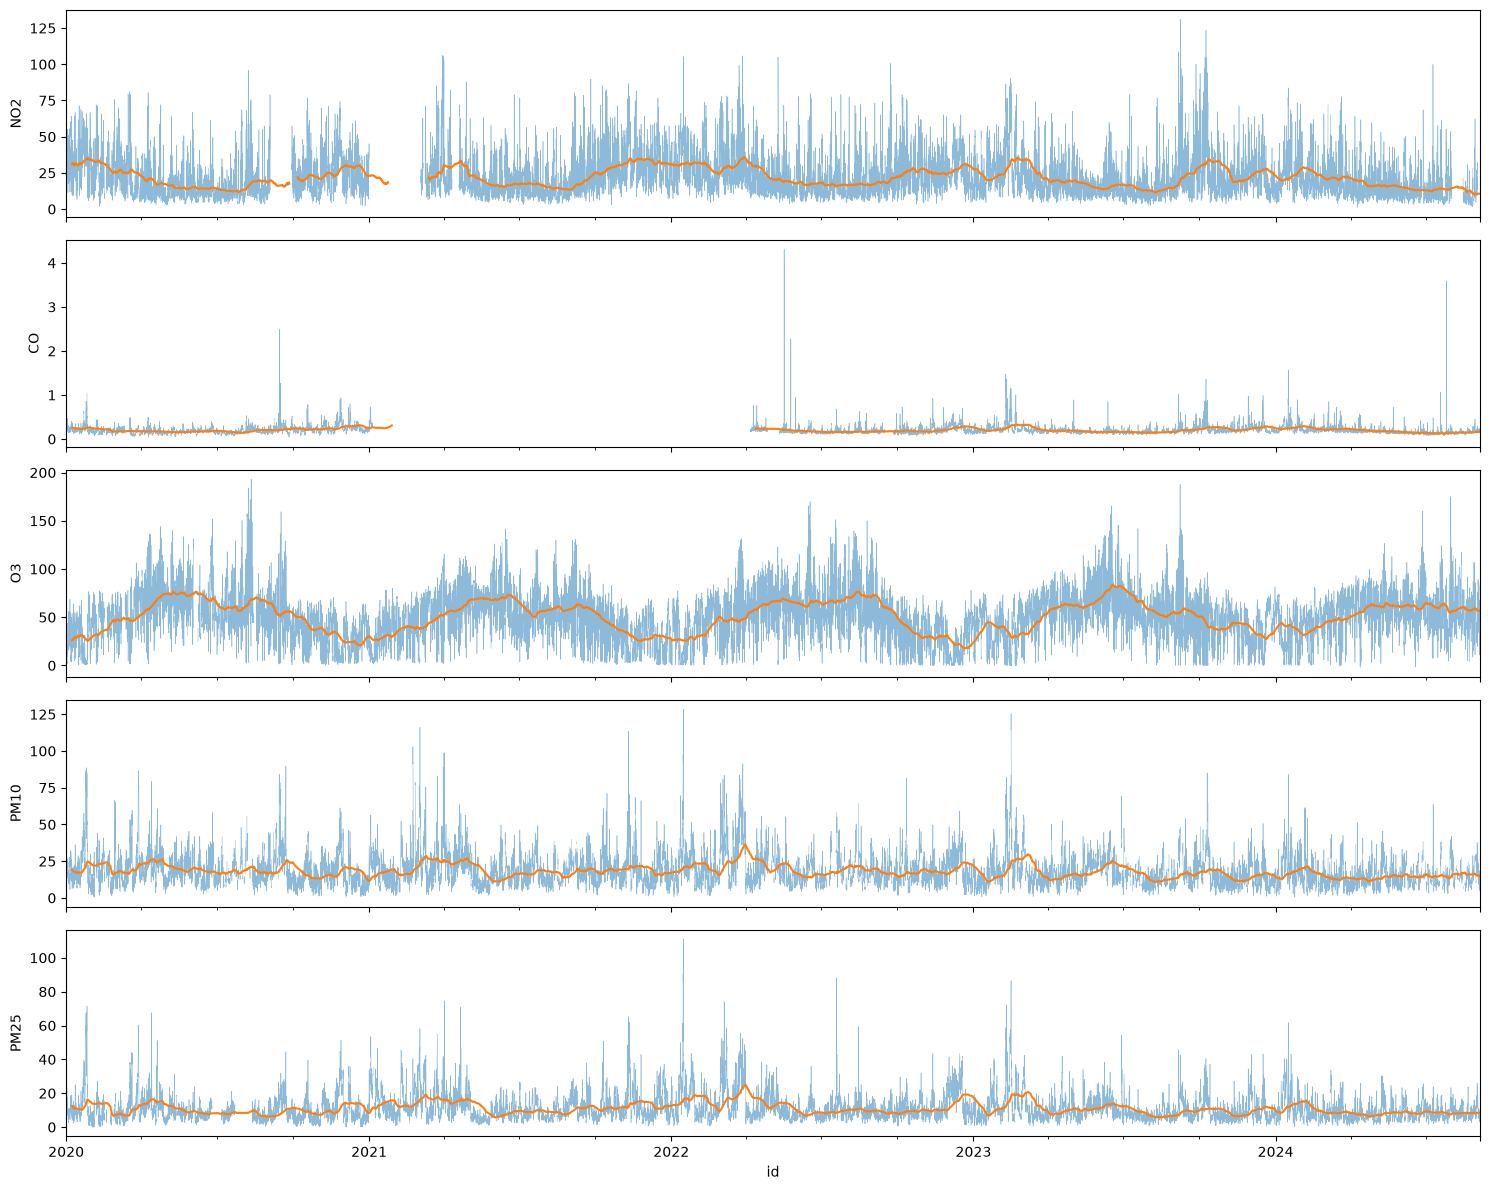

In [30]:
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)
for ax, col in zip(axes, POLLUTANTS):
    train[col].plot(ax=ax, lw=0.4, alpha=0.5)
    train[col].rolling(24 * 30, min_periods=24 * 7).mean().plot(ax=ax, lw=1.5)
    ax.set_ylabel(col.replace("valeur_", ""))

plt.tight_layout()

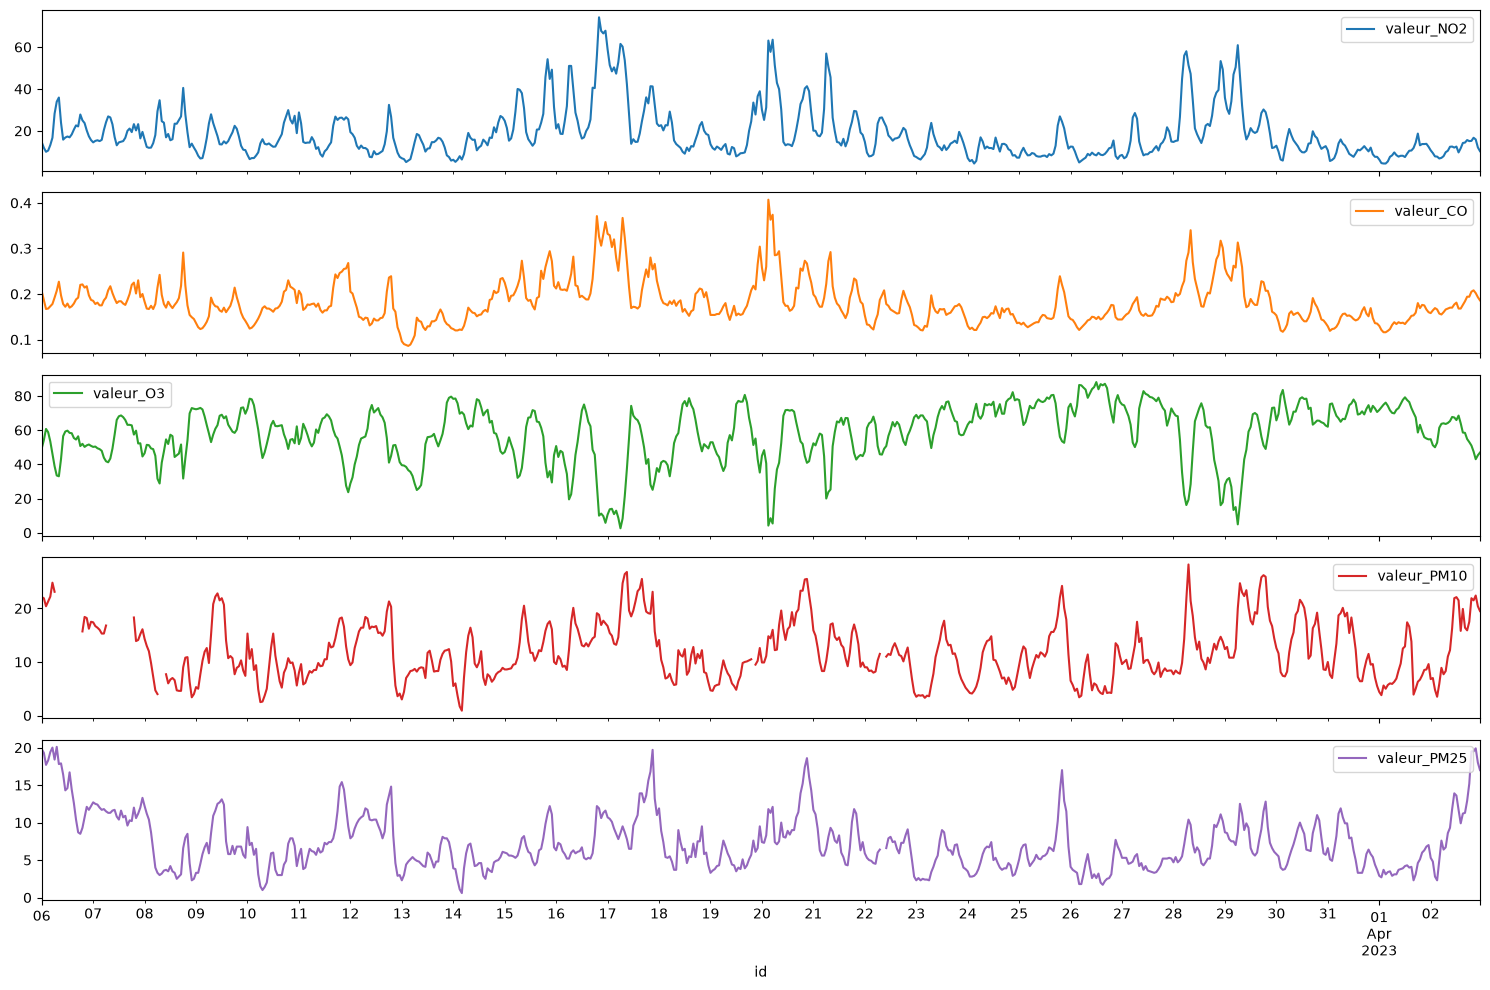

In [31]:
train.loc["2023-03-06":"2023-04-02", POLLUTANTS].plot(subplots=True, figsize=(15, 10))
plt.tight_layout()

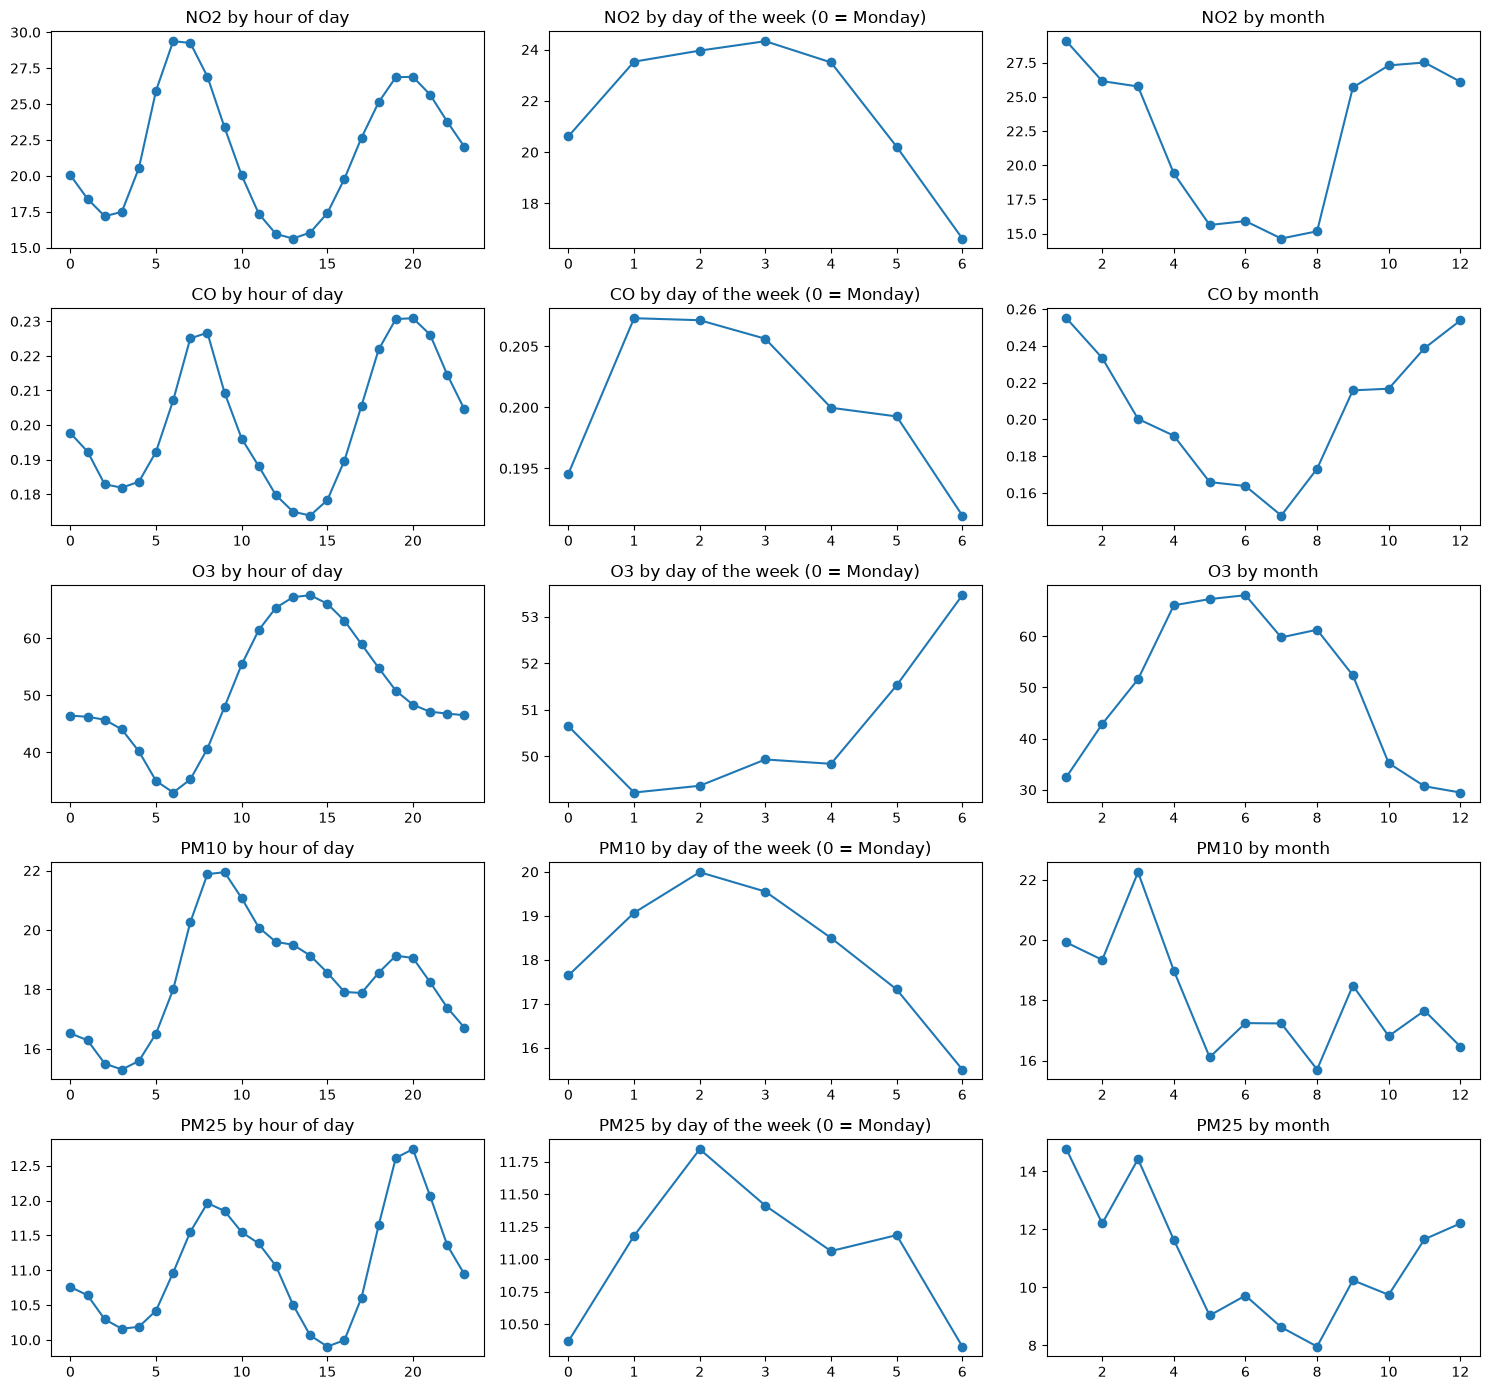

In [32]:
groups = {
    "hour of day": train.index.hour,
    "day of the week (0 = Monday)": train.index.dayofweek,
    "month": train.index.month,
}
fig, axes = plt.subplots(len(POLLUTANTS), 3, figsize=(15, 14))
for i, col in enumerate(POLLUTANTS):
    for j, (name, key) in enumerate(groups.items()):
        train[col].groupby(key).mean().plot(ax=axes[i, j], marker="o")
        axes[i, j].set_title(f"{col.replace('valeur_', '')} by {name}")
        axes[i, j].set_xlabel("")
        
plt.tight_layout()

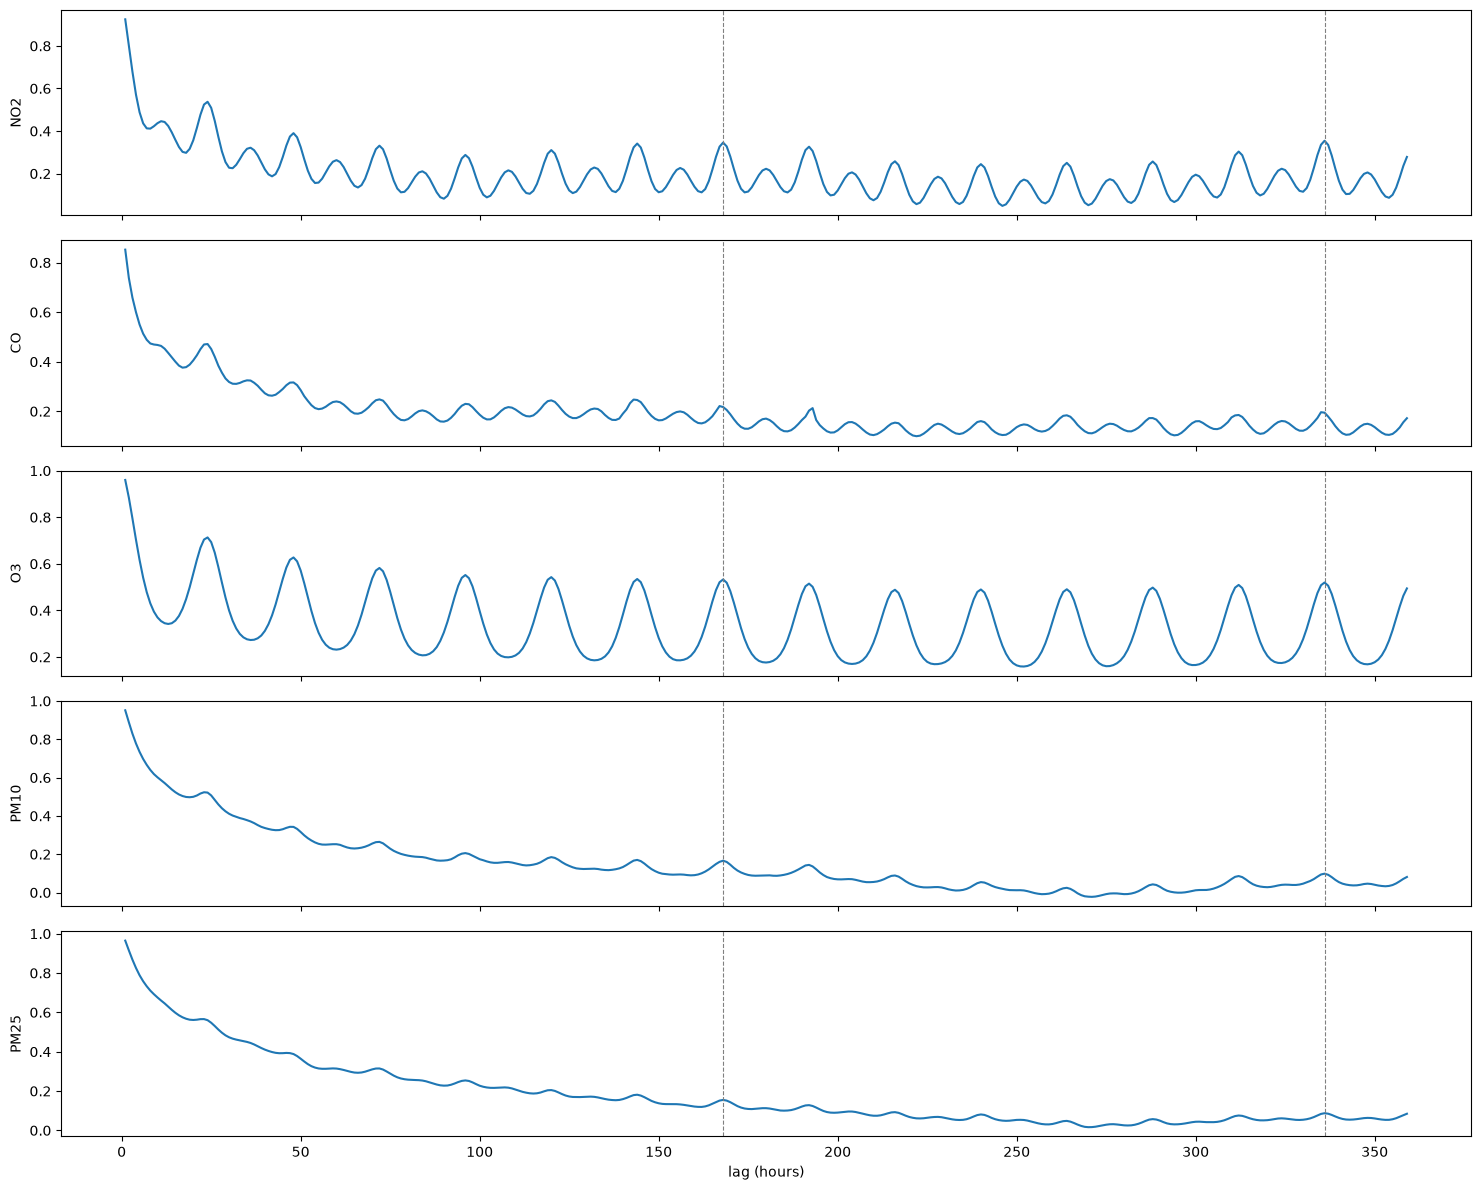

In [33]:
lags = range(1, 24 * 15)
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)
for ax, col in zip(axes, POLLUTANTS):
    ax.plot(lags, [train[col].autocorr(lag) for lag in lags])
    for week in (168, 336):
        ax.axvline(week, color="grey", ls="--", lw=0.8)
    ax.set_ylabel(col.replace("valeur_", ""))
axes[-1].set_xlabel("lag (hours)")
plt.tight_layout()

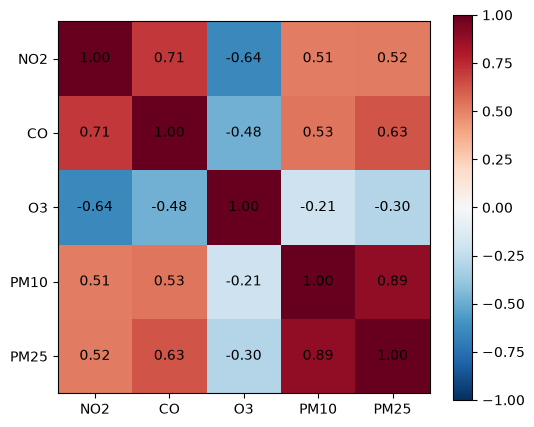

In [34]:
corr = train[POLLUTANTS].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [c.replace("valeur_", "") for c in POLLUTANTS]
ax.set_xticks(range(5), labels)
ax.set_yticks(range(5), labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)

In [35]:
HORIZON = 504

train_fit = train.iloc[:-HORIZON]
valid = train.iloc[-HORIZON:]

assert train_fit.index.max() < valid.index.min()
print("fit: ", train_fit.index.min(), "->", train_fit.index.max())
print("valid: ", valid.index.min(), "->", valid.index.max(), ",", len(valid), "hours")
print("observed values in valid:", valid.count())

fit:  2020-01-01 00:00:00 -> 2024-08-13 22:00:00
valid:  2024-08-13 23:00:00 -> 2024-09-03 22:00:00 , 504 hours
observed values in valid: valeur_NO2     394
valeur_CO      498
valeur_O3      504
valeur_PM10    299
valeur_PM25    491
dtype: int64


In [36]:
def persistence(history, index):
    last = history.ffill().iloc[-1]
    return pd.DataFrame([last.to_numpy()] * len(index), index=index, columns=history.columns)

In [37]:
def seasonal_naive(history, index, season=168):
    # position of each row whitin the season, counted so for forecast starts at phrase 0
    phase = (np.arange(len(history)) - len(history)) % season
    last_season = history.groupby(phase).last() # last non-missing val per phase
    steps = np.arange(len(index)) % season
    return pd.DataFrame(last_season.to_numpy()[steps], index=index, columns=history.columns)

In [38]:
def mae_table(y_true, preds):
    table = pd.DataFrame({name: (y_true - p).abs().mean() for name, p in preds.items()}).T
    table["average"] = table.mean(axis=1)
    return table.round(3)

preds = {
    "persistence": persistence(train_fit, valid.index),
    "seasonal_naive_24": seasonal_naive(train_fit, valid.index, season=24),
    "seasonal_naive_168": seasonal_naive(train_fit, valid.index, season=168),
 }
for p in preds.values():
    assert p.notna().all().all()

mae_table(valid, preds)

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average
persistence,7.429,0.046,16.160,5.622,4.237,6.699
seasonal_naive_24,10.374,0.045,14.254,6.676,4.210,7.112
seasonal_naive_168,9.469,0.044,17.303,6.439,3.555,7.362
